In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim20")
sys.path.append(os.path.curdir + "/sim_store/sim21")
sys.path.append(os.path.pardir+"/crawdad_mobility")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim21_setting import *
from load_crawdad_usr import *
from sub_costs import *


# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [37]:
# Load Crawdad data
# Load All 12 users and trim their info
db_names = []
for i in range(1,13):
    if i != 8 and i != 12:
        db_names += ['LifeMap_GS'+str(i)+'.db']

db = []
for name in db_names:
    print(name)
    name = os.path.pardir+ "/crawdad_mobility/" + name
    df,trace = load_usr(name)
    db += [trace]

LifeMap_GS1.db
LifeMap_GS2.db
LifeMap_GS3.db
LifeMap_GS4.db
LifeMap_GS5.db
LifeMap_GS6.db
LifeMap_GS7.db
LifeMap_GS9.db
LifeMap_GS10.db
LifeMap_GS11.db


In [39]:
# num_user by type
num_users_list = [10,0,10,0]
area_scale_list = [1,2,3,5,8]

In [38]:
num_trials = 10
key = "mig_rate"

for k in range(len(area_scale_list)):
    Batch_cost_stores = []
    SG_cost_stores = []
    Naive_cost_stores = []
    Myopic_cost_stores = []
    Cloud_cost_stores = []
    
    Batch_mig_stores = []
    SG_mig_stores = []
    Naive_mig_stores = []
    Myopic_mig_stores = []
    Cloud_mig_stores = []

    for i in range(num_trials):

        print("Trial Number:",i, "area:", area_scale_list[k])

        while True:
            try:
                users, servers, links, jobs, sim_param = simulation_setting(num_users_list, db, area_scale_list[k])
                Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
                Batch_plan = Migration_Plans(users,jobs,sim_param)
                Batch_plan.from_seq_greedy(Batch_prob)
                Batch_cost_stores += [Cost_Recordings(Batch_plan)]
                break
            except:
                print("batch_broken, repeating with new users")
                continue
                
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Batch_plan.mig_plan_dict[u][key])
        Batch_mig_stores += [num_mig_cumul]


        # Make SG Prob
        # Set Refresh to false for SG
        refresh_rate = [0,0]
        refresh = False

        jobs2 = copy.deepcopy(jobs)
        for j in range(len(jobs2)):
            jobs2[j].info_from_usr(users[j],refresh_rate,refresh)

        # print("SG prob...")
        SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
        SG_plan = Migration_Plans(users,jobs2,sim_param)
        SG_plan.from_seq_greedy(SG_prob)
        SG_cost_stores += [Cost_Recordings(SG_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(SG_plan.mig_plan_dict[u][key])
        SG_mig_stores += [num_mig_cumul]

        # Make Cloud Prob
        # print("Cloud prob...")
        Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
        Cloud_plan = Migration_Plans(users,jobs,sim_param)
        Cloud_plan.from_seq_greedy(Cloud_prob)
        Cloud_cost_stores += [Cost_Recordings(Cloud_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Cloud_plan.mig_plan_dict[u][key])
        Cloud_mig_stores += [num_mig_cumul]

        # Make Naive Prob
        # print("Naive prob...")
        Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
        Naive_plan = Migration_Plans(users,jobs,sim_param)
        Naive_plan.from_seq_greedy(Naive_prob)
        Naive_cost_stores += [Cost_Recordings(Naive_plan)]
        # print("done!")
        num_mig_cumul = 0
        Naive_mig_stores += [num_mig_cumul]

        # Make Myopic Prob
        # print("Myopic prob...")
        Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
        Myopic_plan = Migration_Plans(users,jobs,sim_param)
        Myopic_plan.from_seq_greedy(Myopic_prob)
        Myopic_cost_stores += [Cost_Recordings(Myopic_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Myopic_plan.mig_plan_dict[u][key])
        Myopic_mig_stores += [num_mig_cumul]

        
    cost_stores_dic = {}
    cost_stores_dic["SG"] = SG_cost_stores
    cost_stores_dic["Batch"] = Batch_cost_stores
    cost_stores_dic["Naive"] = Naive_cost_stores
    cost_stores_dic["Myopic"] = Myopic_cost_stores
    cost_stores_dic["Cloud"] = Cloud_cost_stores

    pickle.dump(cost_stores_dic, open(os.path.curdir + "/sim_store/sim21/n1_cost_store_a"+ str(area_scale_list[k]) +".p", "wb" ) )

    
    mig_stores_dict = {}
    mig_stores_dict['SG'] = SG_mig_stores
    mig_stores_dict['Batch'] = Batch_mig_stores
    mig_stores_dict['Naive'] = Naive_mig_stores
    mig_stores_dict['Myopic'] = Myopic_mig_stores
    mig_stores_dict['Cloud'] = Cloud_mig_stores
    pickle.dump(mig_stores_dict, open(os.path.curdir + "/sim_store/sim21/n1_mig_store_a"+ str(area_scale_list[k]) +".p", "wb" ) )

    

Trial Number: 0 area: 8
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
Trial Number: 1 area: 8
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
Trial Number: 2 area: 8
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
Trial Number: 3 area: 8
Trial Number: 4 area: 8
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough 

### Make figures with cost
1. User Density vs. Total Cost per User
2. User Density vs. Latency Cost per User

In [40]:
latencies_SG = []
latencies_Batch = []
latencies_Myopic = []
latencies_Cloud = []
latencies_Naive = []

total_costs_SG = []
total_costs_Batch = []
total_costs_Myopic = []
total_costs_Cloud = []
total_costs_Naive = []

latencies_SG_var = []
latencies_Batch_var = []
latencies_Myopic_var = []
latencies_Cloud_var = []
latencies_Naive_var = []

total_costs_SG_var = []
total_costs_Batch_var = []
total_costs_Myopic_var = []
total_costs_Cloud_var = []
total_costs_Naive_var = []

for i in range(len(area_scale_list)):
    # open a file, where you stored the pickled data
    name = "/sim_store/sim21/n1_cost_store_a"+ str(area_scale_list[i]) +".p"
    total_users = np.sum(num_users_list)
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)

    SG_cost, Batch_cost, Myopic_cost, Naive_cost, Cloud_cost = obtain_sub_costs(data)
    latencies_SG += [SG_cost[3]/total_users]
    latencies_Batch += [Batch_cost[3]/total_users]
    latencies_Myopic += [Myopic_cost[3]/total_users]
    latencies_Cloud += [Cloud_cost[3]/total_users]
    latencies_Naive += [Naive_cost[3]/total_users]
    
    total_costs_SG += [SG_cost[0]/total_users]
    total_costs_Batch += [Batch_cost[0]/total_users]
    total_costs_Myopic += [Myopic_cost[0]/total_users]
    total_costs_Cloud += [Cloud_cost[0]/total_users]
    total_costs_Naive += [Naive_cost[0]/total_users]
    
    cost_var, lat_var = obtain_sub_vars(data)
    
    latencies_SG_var += [lat_var['SG']/total_users]
    latencies_Batch_var += [lat_var['Batch']/total_users]
    latencies_Myopic_var += [lat_var['Myopic']/total_users]
    latencies_Cloud_var += [lat_var['Cloud']/total_users]
    latencies_Naive_var += [lat_var['Naive']/total_users]

    total_costs_SG_var += [cost_var['SG']/total_users]
    total_costs_Batch_var += [cost_var['Batch']/total_users]
    total_costs_Myopic_var += [cost_var['Myopic']/total_users]
    total_costs_Cloud_var += [cost_var['Cloud']/total_users]
    total_costs_Naive_var += [cost_var['Naive']/total_users]
    
    name2 = "/sim_store/sim21/n1_mig_store_a"+ str(area_scale_list[i]) +".p"
    file = open(os.path.curdir + name, 'rb')


In [41]:
print("SG total cost:", total_costs_SG)
print("Bt total cost:", total_costs_Batch)
print("My total cost:", total_costs_Myopic)
print("Cl total cost:", total_costs_Cloud)
print("Na total cost:", total_costs_Naive)

print("SG total var:", total_costs_SG_var)
print("Bt total var:", total_costs_Batch_var)
print("My total var:", total_costs_Myopic_var)
print("Cl total var:", total_costs_Cloud_var)
print("Na total var:", total_costs_Naive_var)


SG total cost: [5.511767788980978, 5.550384856410554, 5.638504298522727, 5.340854686711384, 5.092500081571482]
Bt total cost: [3.99952781677734, 3.8998401001198104, 3.8761050816350275, 3.8155608887675667, 3.5823763858004]
My total cost: [4.652970342934578, 4.607307359207896, 4.728544233721759, 4.43967676901456, 4.046088795804521]
Cl total cost: [6.876917337132191, 6.125660050398078, 6.569854496732023, 6.17424953232926, 6.112918505496454]
Na total cost: [6.945254838410628, 7.120669893619686, 7.433523913651382, 7.045910865516609, 6.745467017087192]
SG total var: [0.761974008258597, 0.7848778983450808, 1.306818432585422, 0.9443506535853127, 1.0168143669749339]
Bt total var: [0.24286043731998622, 0.29584749887300416, 0.6993993414298831, 0.6020795034406179, 0.6583031822861712]
My total var: [0.28190723237154314, 0.4386593010615837, 0.5898162183865469, 0.619080291432788, 0.7038050036429215]
Cl total var: [1.0444175771744424, 1.2521654924433003, 1.5869935572368408, 1.534522740280889, 1.851576

In [42]:
print("SG latency cost:", latencies_SG)
print("Bt latency cost:", latencies_Batch)
print("My latency cost:", latencies_Myopic)
print("Cl latency cost:", latencies_Cloud)
print("Na latency cost:", latencies_Naive)

print("SG latency cost:", latencies_SG_var)
print("Bt latency cost:", latencies_Batch_var)
print("My latency cost:", latencies_Myopic_var)
print("Cl latency cost:", latencies_Cloud_var)
print("Na latency cost:", latencies_Naive_var)

SG latency cost: [3.96118276910284, 4.046035168562729, 4.082545123390661, 3.8540038425792567, 3.6270688755408016]
Bt latency cost: [2.2147853839468863, 2.177529536598654, 2.1180377546052256, 2.1571606770756757, 1.9932963499178662]
My latency cost: [2.566466349248793, 2.5911800626098165, 2.710353478528551, 2.567095663959141, 2.327468231715661]
Cl latency cost: [5.316448886106502, 4.612695898758385, 5.003269927311591, 4.671903288813235, 4.620866795427129]
Na latency cost: [5.532088548174182, 5.755797711062047, 6.042652207151707, 5.6752909233847095, 5.384492210511723]
SG latency cost: [0.7445910123090952, 0.7453382620652302, 1.2999263595480042, 0.9116144168148118, 0.9532846849472969]
Bt latency cost: [0.20238344556911433, 0.2539262941771168, 0.677932349864667, 0.5316516368403621, 0.6045667109080199]
My latency cost: [0.22982050156672468, 0.33153997999749035, 0.5378231889613193, 0.5191209014396799, 0.6313993610993811]
Cl latency cost: [1.0023732688418137, 1.1836038698405689, 1.563961322352

Text(0,0.5,'Total Cost per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


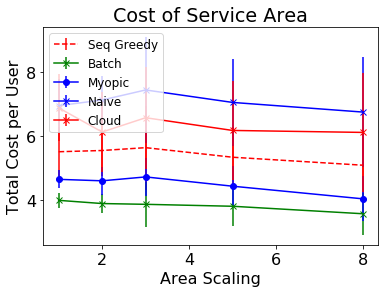

In [43]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = area_scale_list

plt.errorbar(x_ax, total_costs_SG, total_costs_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, total_costs_Batch, total_costs_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, total_costs_Myopic, total_costs_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, total_costs_Naive, total_costs_Naive_var, color = 'blue', marker =  'x', label = 'Naive')
plt.errorbar(x_ax, total_costs_Cloud, total_costs_Cloud_var, color = 'red', marker ='x', label = 'Cloud')

# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'upper left', prop={'size': 12})# plt.ylim(0,)


plt.title('Cost of Service Area')
plt.xlabel('Area Scaling')
plt.ylabel('Total Cost per User')

Text(0,0.5,'Latency Cost per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


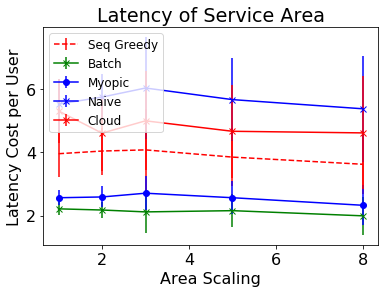

In [44]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = area_scale_list

plt.errorbar(x_ax, latencies_SG, latencies_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, latencies_Batch, latencies_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, latencies_Myopic, latencies_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, latencies_Naive, latencies_Naive_var, color = 'blue', marker =  'x', label = 'Naive')
plt.errorbar(x_ax, latencies_Cloud, latencies_Cloud_var, color = 'red', marker ='x', label = 'Cloud')


# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'upper left', prop={'size': 12})# plt.ylim(-0.2,)


plt.title('Latency of Service Area')
plt.xlabel('Area Scaling')
plt.ylabel('Latency Cost per User')

In [45]:
# Migration and user density
mig_SG = []
mig_Batch = []
mig_Myopic = []
mig_Cloud = []
mig_Naive = []

mig_SG_var = []
mig_Batch_var = []
mig_Myopic_var = []
mig_Cloud_var = []
mig_Naive_var = []

for i in range(len(area_scale_list)):
    # open a file, where you stored the pickled data
    name = "/sim_store/sim21/mig_store_a"+ str(area_scale_list[i]) +".p"
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)
    
    mig_SG += [np.divide(np.mean(data['SG']), np.sum(num_users_list))]
    mig_Batch += [np.divide(np.mean(data['Batch']), np.sum(num_users_list))]
    mig_Myopic += [np.divide(np.mean(data['Myopic']), np.sum(num_users_list))]
    mig_Cloud += [np.divide(np.mean(data['Cloud']), np.sum(num_users_list))]
    mig_Naive += [np.divide(np.mean(data['Naive']), np.sum(num_users_list))]
    
    mig_SG_var += [np.divide(np.std(data['SG']), np.sum(num_users_list))]
    mig_Batch_var += [np.divide(np.std(data['Batch']), np.sum(num_users_list))]
    mig_Myopic_var += [np.divide(np.std(data['Myopic']), np.sum(num_users_list))]
    mig_Cloud_var += [np.divide(np.std(data['Cloud']), np.sum(num_users_list))]
    mig_Naive_var += [np.divide(np.std(data['Naive']), np.sum(num_users_list))]

Text(0,0.5,'Migrations per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


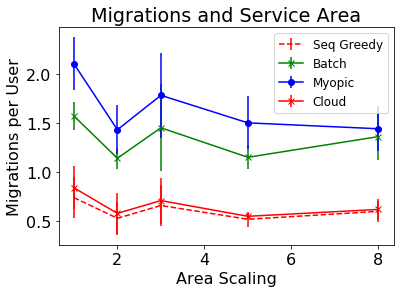

In [46]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = area_scale_list

plt.errorbar(x_ax, mig_SG, mig_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, mig_Batch, mig_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, mig_Myopic, mig_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, mig_Cloud, mig_Cloud_var, color = 'red', marker ='x', label = 'Cloud')


# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'best', prop={'size': 12})# plt.ylim(-0.2,)
# plt.ylim(-0.2,)


plt.title('Migrations and Service Area')
plt.xlabel('Area Scaling')
plt.ylabel('Migrations per User')